# Bike Sharing Demand Prediction (Seoul)

Predict how many bikes are rented in each hour from weather and calendar features.

- Dataset: [Seoul Bike Sharing Demand (UCI)](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand), CC BY 4.0, 8,760 hourly rows
- Put `SeoulBikeData.csv` in a `data/` folder next to this notebook
- Model: Random Forest Regressor
- Evaluation: train and test are split by whole days, so hours from the same day never sit on both sides

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

DATA_PATH = Path("data/SeoulBikeData.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("SeoulBikeData.csv")   # also works if the csv sits next to the notebook

dataset = pd.read_csv(DATA_PATH, encoding='latin1')
dataset.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [3]:
dataset.shape

(8760, 14)

In [4]:
dataset.columns

Index(['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)',
       'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)',
       'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons',
       'Holiday', 'Functioning Day'],
      dtype='str')

In [5]:
dataset.describe()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


In [6]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13  Functioning Day            8760 non-null   str    
dtypes: 

In [7]:
print("\nMissing Values per Column:")
print(dataset.isnull().sum())


Missing Values per Column:
Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
dtype: int64


In [8]:
import pandas as pd
import numpy as np

# Work on a copy so the original dataframe stays untouched
df_explore = dataset.copy()

# 1. Check for exact duplicate rows
duplicates = df_explore.duplicated().sum()
print(f"Total Duplicate Rows: {duplicates}")

# 2. Inspect Unique Values for Categorical Columns
# This ensures there are no hidden spelling errors (e.g., 'Winter' vs 'winter ')
print("\nUnique values in text columns:")
for col in ['Seasons', 'Holiday', 'Functioning Day']:
    print(f"{col}: {df_explore[col].unique()}")
# 1. Querying the extremes: Hours with 0 bike rentals
zero_rentals = df_explore[df_explore['Rented Bike Count'] == 0]
print(f"\nHours with exactly 0 rentals: {len(zero_rentals)}")

# If there are 0 rentals, let's see why by looking at the 'Functioning Day' column
if len(zero_rentals) > 0:
    print("Breakdown of 0 rental hours by Functioning Day status:")
    print(zero_rentals['Functioning Day'].value_counts())

# 2. Querying the absolute peak demand
# What did the weather look like during the top 5 busiest hours?
peak_demand = df_explore.nlargest(5, 'Rented Bike Count')
print("\nTop 5 Busiest Hours in the Dataset:")
display(peak_demand[['Date', 'Hour', 'Rented Bike Count', 'Temperature(°C)', 'Seasons']])

Total Duplicate Rows: 0

Unique values in text columns:
Seasons: <StringArray>
['Winter', 'Spring', 'Summer', 'Autumn']
Length: 4, dtype: str
Holiday: <StringArray>
['No Holiday', 'Holiday']
Length: 2, dtype: str
Functioning Day: <StringArray>
['Yes', 'No']
Length: 2, dtype: str

Hours with exactly 0 rentals: 295
Breakdown of 0 rental hours by Functioning Day status:
Functioning Day
No    295
Name: count, dtype: int64

Top 5 Busiest Hours in the Dataset:


,Date,Hour,Rented Bike Count,Temperature(°C),Seasons
4818,19/06/2018,18,3556,24.1,Summer
4866,21/06/2018,18,3418,27.8,Summer
4650,12/06/2018,18,3404,24.9,Summer
4842,20/06/2018,18,3384,27.0,Summer
4458,04/06/2018,18,3380,24.4,Summer


In [9]:
# 1. Calculate Skewness for numerical features
numeric_cols = df_explore.select_dtypes(include=[np.number])
skewness = numeric_cols.skew().sort_values(ascending=False)

print("\nSkewness of Numerical Columns:")
print(skewness)


Skewness of Numerical Columns:
Rainfall(mm)                 14.533232
Snowfall (cm)                 8.440801
Solar Radiation (MJ/m2)       1.504040
Rented Bike Count             1.153428
Wind speed (m/s)              0.890955
Humidity(%)                   0.059579
Hour                          0.000000
Temperature(°C)              -0.198326
Dew point temperature(°C)    -0.367298
Visibility (10m)             -0.701786
dtype: float64


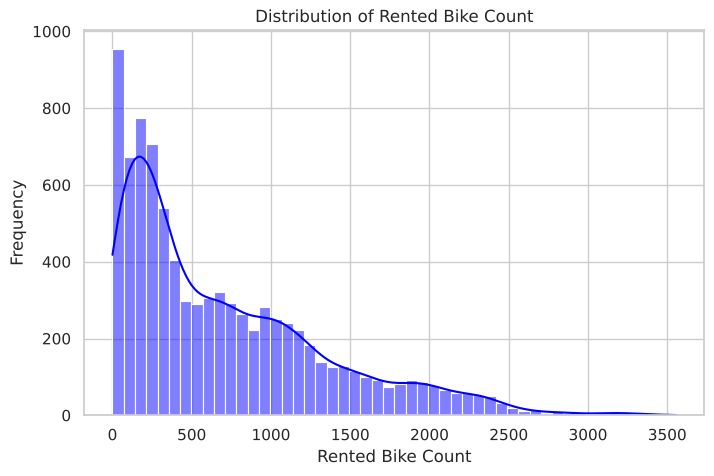

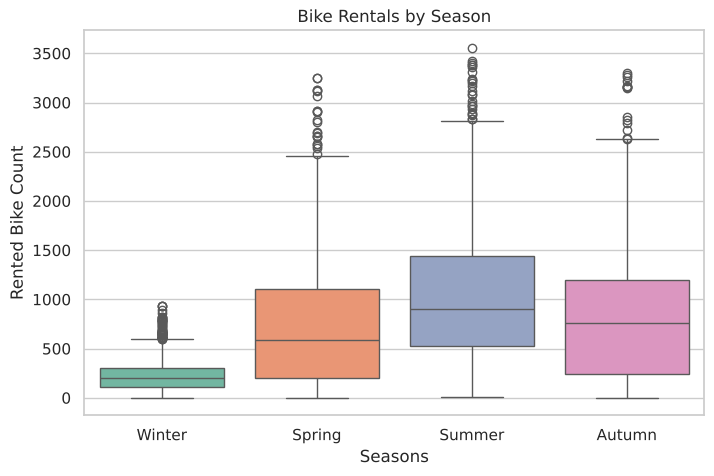

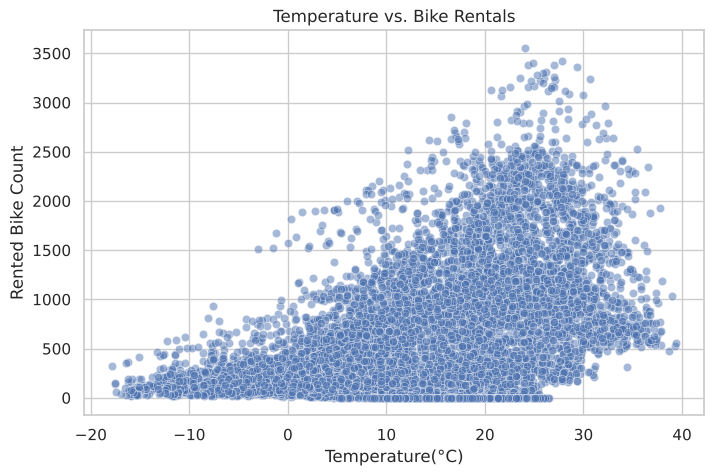

In [10]:
# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
sns.histplot(dataset['Rented Bike Count'], bins=50, kde=True, color='blue')
plt.title('Distribution of Rented Bike Count')
plt.xlabel('Rented Bike Count')
plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(x='Seasons', y='Rented Bike Count', hue='Seasons', data=dataset, palette='Set2', legend=False)
plt.title('Bike Rentals by Season')
plt.show()

plt.figure(figsize=(8, 5))
sns.scatterplot(x='Temperature(°C)', y='Rented Bike Count', data=dataset, alpha=0.5)
plt.title('Temperature vs. Bike Rentals')
plt.show()

In [11]:
# Data Preparation for model training and evaluation
# Work on a copy so this cell can be re-run safely
model_df = dataset.copy()

# Hours when the system was not functioning always have 0 rentals (every zero-rental
# hour in this dataset is one of them). That is not demand, so those rows are removed.
model_df = model_df[model_df['Functioning Day'] == 'Yes'].drop(columns='Functioning Day')

model_df['Date'] = pd.to_datetime(model_df['Date'], format='%d/%m/%Y')

# Keep the calendar day of every row, used later to split train/test by whole days
day_groups = model_df['Date'].dt.strftime('%Y-%m-%d').to_numpy()

model_df['Month'] = model_df['Date'].dt.month
model_df['DayOfWeek'] = model_df['Date'].dt.dayofweek   # 0=Monday, 6=Sunday
# Year (nearly constant here) and day-of-month are not used. Together with Month they
# let the model recognise one specific date, which is memorising, not learning.
model_df = model_df.drop(columns='Date')

model_df = pd.get_dummies(model_df, columns=['Seasons', 'Holiday'], drop_first=True)
model_df = model_df.reset_index(drop=True)
display(model_df.head())

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Month,DayOfWeek,Seasons_Spring,Seasons_Summer,Seasons_Winter,Holiday_No Holiday
0,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,12,4,False,False,True,True
1,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,12,4,False,False,True,True
2,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,12,4,False,False,True,True
3,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,12,4,False,False,True,True
4,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,12,4,False,False,True,True


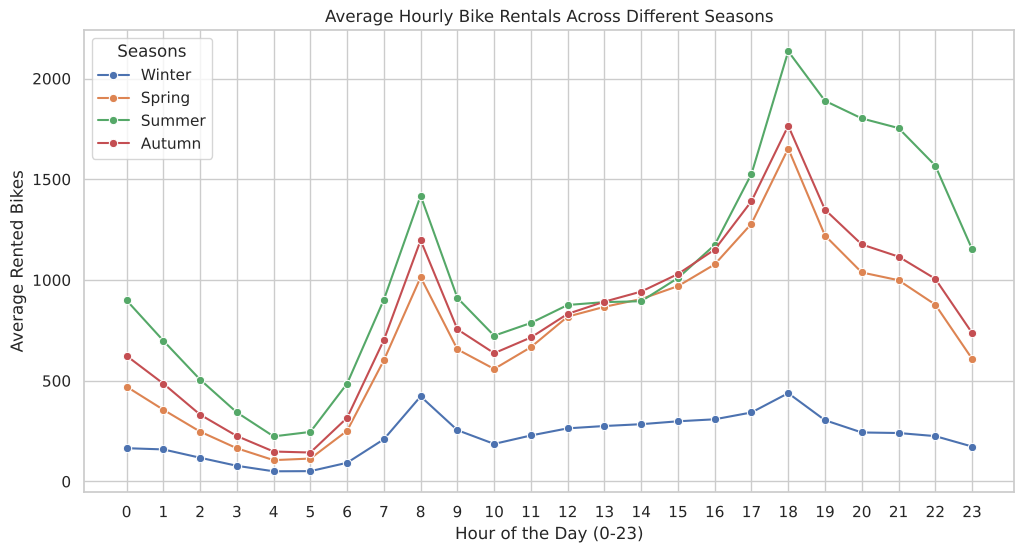

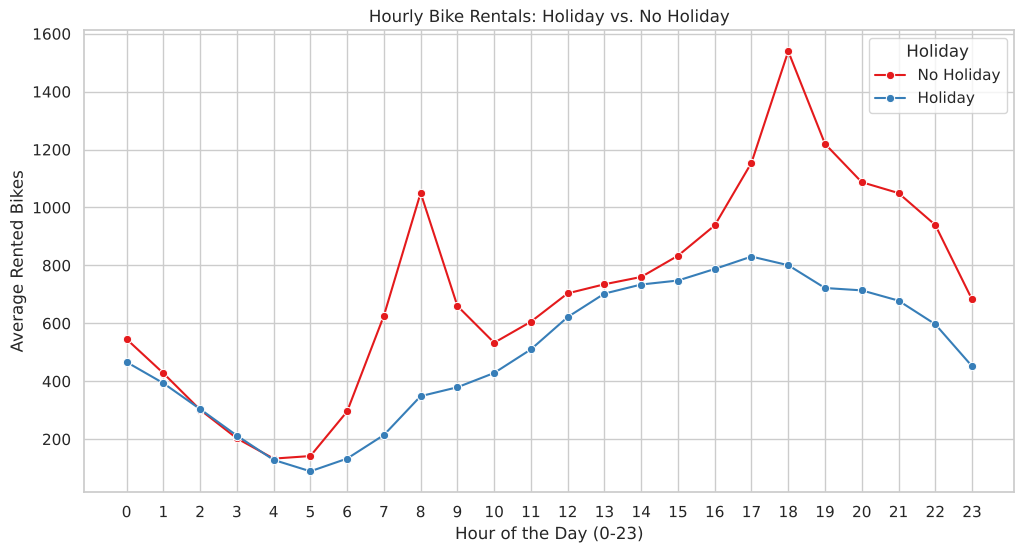

In [12]:
# Hourly trends
df_eda = dataset.copy()
sns.set_theme(style="whitegrid")

# 1. Hourly Trend by Season
plt.figure(figsize=(12, 6))
sns.lineplot(x='Hour', y='Rented Bike Count', hue='Seasons', data=df_eda, errorbar=None, marker='o')
plt.title('Average Hourly Bike Rentals Across Different Seasons')
plt.xlabel('Hour of the Day (0-23)')
plt.ylabel('Average Rented Bikes')
plt.xticks(range(0, 24))
plt.show()

# 2. Hourly Trend by Holiday (Commuter vs. Leisure behavior)
plt.figure(figsize=(12, 6))
sns.lineplot(x='Hour', y='Rented Bike Count', hue='Holiday', data=df_eda, errorbar=None, palette='Set1', marker='o')
plt.title('Hourly Bike Rentals: Holiday vs. No Holiday')
plt.xlabel('Hour of the Day (0-23)')
plt.ylabel('Average Rented Bikes')
plt.xticks(range(0, 24))
plt.show()

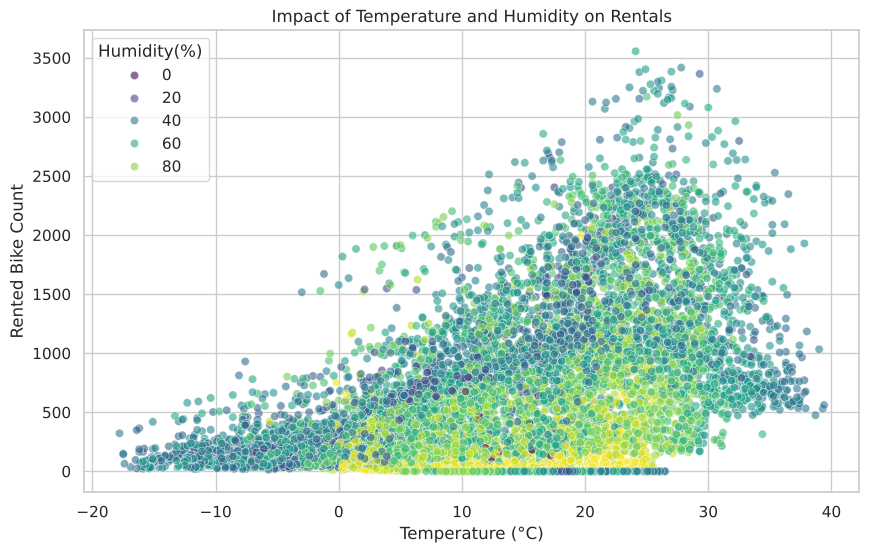

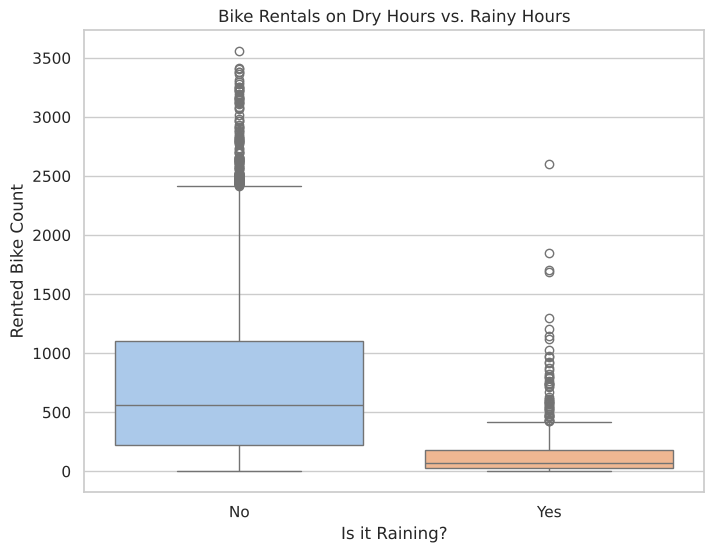

In [13]:
# 3. Temperature vs. Rentals (with Humidity as a color scale)
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Temperature(°C)', y='Rented Bike Count', hue='Humidity(%)',
                palette='viridis', data=df_eda, alpha=0.6)
plt.title('Impact of Temperature and Humidity on Rentals')
plt.xlabel('Temperature (°C)')
plt.ylabel('Rented Bike Count')
plt.show()

# 4. Impact of Rainfall (binary "Did it rain?" category for easier viewing)
df_eda['Raining'] = df_eda['Rainfall(mm)'].apply(lambda x: 'Yes' if x > 0 else 'No')

plt.figure(figsize=(8, 6))
sns.boxplot(x='Raining', y='Rented Bike Count', hue='Raining', data=df_eda, palette='pastel', legend=False)
plt.title('Bike Rentals on Dry Hours vs. Rainy Hours')
plt.xlabel('Is it Raining?')
plt.ylabel('Rented Bike Count')
plt.show()

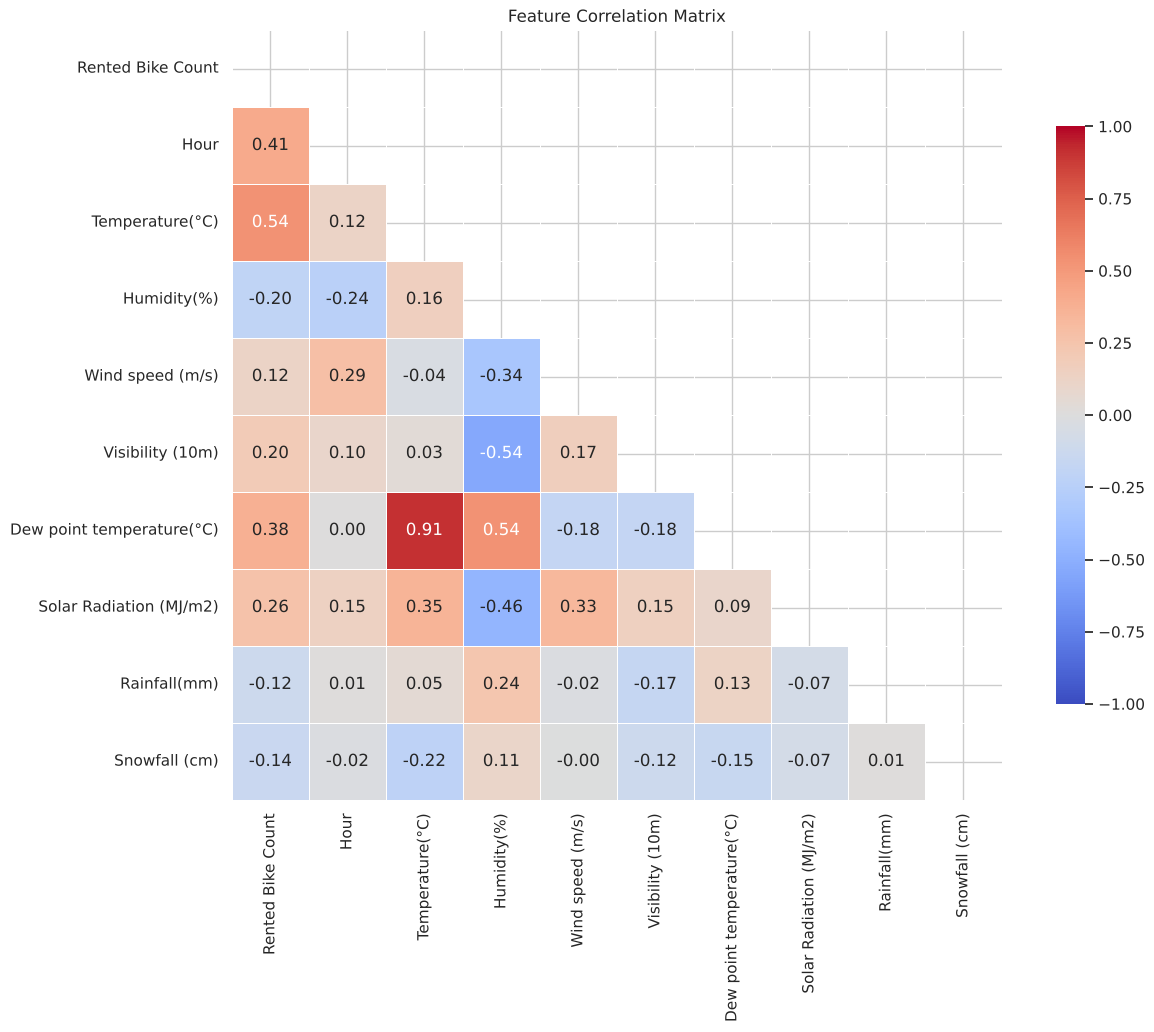

In [14]:
# 5. Masked correlation heatmap
plt.figure(figsize=(14, 10))

# Numerical columns only, so text columns do not cause errors
numeric_cols = dataset.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()

# Hide the upper triangle, it is just a mirror image
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap='coolwarm',
            vmax=1, vmin=-1, square=True, linewidths=.5, cbar_kws={"shrink": .75})
plt.title('Feature Correlation Matrix')
plt.show()

In [15]:
# Building the model
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

X = model_df.drop('Rented Bike Count', axis=1)
y = model_df['Rented Bike Count']

# Split by whole days: all 24 hours of a day go to train OR test.
# A random row split puts 11 AM in train and 12 noon of the same day in test,
# and the score can look better than what the model would do on a new day.
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups=day_groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = day_groups[train_idx]
print(f"Train: {len(X_train)} rows ({len(set(groups_train))} days), Test: {len(X_test)} rows")

# n_estimators=100 means the model builds 100 decision trees
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Predictions on the unseen test days
y_pred = rf_model.predict(X_test)

Train: 6761 rows (282 days), Test: 1704 rows


R-squared (R2) Score: 0.9258 (Closer to 1.0 is better)
Root Mean Squared Error (RMSE): 174.44
Mean Absolute Error (MAE): 111.11


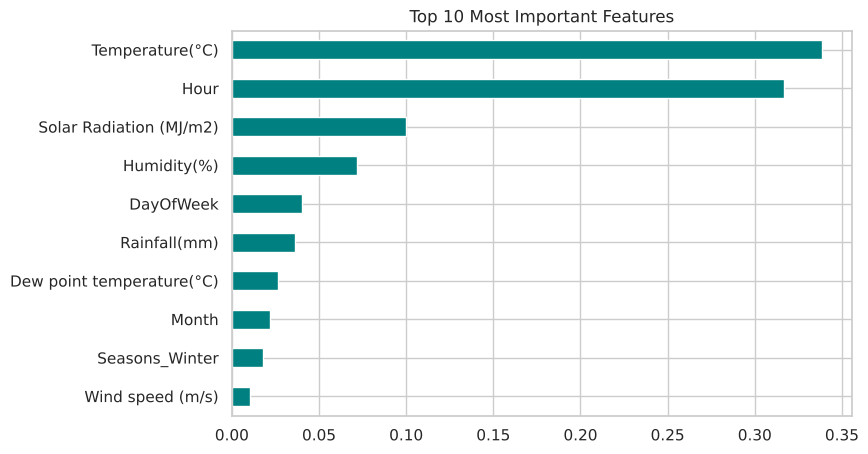

In [16]:
# Evaluate the Model's Performance
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
print(f"R-squared (R2) Score: {r2:.4f} (Closer to 1.0 is better)")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
feature_importances.nlargest(10).plot(kind='barh', figsize=(8, 5), color='teal')
plt.title('Top 10 Most Important Features')
plt.gca().invert_yaxis()
plt.show()

In [17]:
# Tuning the random forest
from sklearn.model_selection import GridSearchCV, GroupKFold

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10]
}

# GroupKFold keeps each day inside one fold, same idea as the train/test split above
grid_search = GridSearchCV(estimator=RandomForestRegressor(random_state=42),
                           param_grid=param_grid,
                           cv=GroupKFold(n_splits=3),
                           scoring='neg_mean_squared_error',
                           n_jobs=-1)
grid_search.fit(X_train, y_train, groups=groups_train)

print("Best Settings Found: ", grid_search.best_params_)
best_model = grid_search.best_estimator_
y_pred_optimized = best_model.predict(X_test)
print(f"Baseline  R-squared: {r2_score(y_test, y_pred):.4f}")
print(f"Optimized R-squared: {r2_score(y_test, y_pred_optimized):.4f}")

Best Settings Found:  {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}
Baseline  R-squared: 0.9258
Optimized R-squared: 0.9261
